# MSI 2026 — Early game vs objective control

**Question:** At MSI 2026, do teams that win more stand out in the early game (gold at 15, first tower) or in objective control (dragons, Baron)?

- Data: `data/msi26.db` built by `src/clean.py` → `src/load_db.py` (source: Kaggle *League of Legends MSI 2026*, Eduardo Stückrath, CC BY 4.0; Oracle's Elixir + Liquipedia).
- Method: **descriptive only.** Rankings, Spearman correlation, group means. n = 11 teams, so no p-values and no causal language.
- Rates are in percentage points (0–100). `winrate = wins / games_played × 100`.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB, FIG = ROOT / "data" / "msi26.db", ROOT / "figures"
FIG.mkdir(exist_ok=True)

with sqlite3.connect(DB) as con:
    teams = pd.read_sql("SELECT * FROM teams", con)
    players = pd.read_sql("SELECT * FROM players", con)
    champs = pd.read_sql("SELECT * FROM champions", con)

ABBR = {"Bilibili Gaming": "BLG", "Deep Cross Gaming": "DCG", "FURIA": "FUR", "G2 Esports": "G2",
        "Hanwha Life Esports": "HLE", "Karmine Corp": "KC", "LYON": "LYON", "T1": "T1",
        "Team Liquid": "TL", "Team Secret Whales": "TSW", "Top Esports": "TES"}
teams["abbr"] = teams.team.map(ABBR)

EARLY = ["gold_diff_15", "first_tower_rate", "first_blood_rate", "first_to_three_towers_rate"]
OBJ = ["dragon_control_rate", "baron_control_rate", "grub_control_rate", "first_dragon_rate"]
LABEL = {
    "gold_diff_15": "Gold diff @15 (gold)", "first_tower_rate": "First tower rate (%)",
    "first_blood_rate": "First blood rate (%)", "first_to_three_towers_rate": "First to 3 towers rate (%)",
    "dragon_control_rate": "Dragon control (%)", "baron_control_rate": "Baron control (%)",
    "grub_control_rate": "Void grub control (%)", "first_dragon_rate": "First dragon rate (%)",
}
GROUP = {**{m: "Early game" for m in EARLY}, **{m: "Objective control" for m in OBJ}}

# Palette: reference categorical slots 1-2 (validated all-pairs), recessive ink/grid
BLUE, ORANGE = "#2a78d6", "#eb6834"
GCOLOR = {"Early game": BLUE, "Objective control": ORANGE}
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlecolor": INK, "axes.titlelocation": "left",
})

def finish(fig, note, name=None):
    """Reading note under every chart; optional save to figures/."""
    fig.text(0.01, -0.02, note, ha="left", va="top", fontsize=9, color=INK2, wrap=True)
    if name:
        fig.savefig(FIG / name, dpi=200, bbox_inches="tight")
    plt.show()

def rho(df, m, y="winrate"):
    return df[m].corr(df[y], method="spearman")

print({k: v.shape for k, v in {"teams": teams, "players": players, "champions": champs}.items()})

{'teams': (11, 32), 'players': (55, 29), 'champions': (101, 21)}


## Part A — Exploratory analysis (Step 5)

### A1. Team ranking

In [2]:
rank = (teams[["team", "abbr", "games_played", "wins", "loses", "winrate"]]
        .sort_values(["winrate", "games_played"], ascending=False).reset_index(drop=True))
rank.index += 1
rank

,team,abbr,games_played,wins,loses,winrate
1,T1,T1,21,15,6,71.43
2,Hanwha Life Esports,HLE,20,13,7,65.00
3,Bilibili Gaming,BLG,17,11,6,64.71
4,LYON,LYON,17,11,6,64.71
5,Team Liquid,TL,12,6,6,50.00
6,G2 Esports,G2,15,6,9,40.00
7,Karmine Corp,KC,9,3,6,33.33
8,Top Esports,TES,9,3,6,33.33
9,Team Secret Whales,TSW,10,3,7,30.00
10,Deep Cross Gaming,DCG,6,0,6,0.00


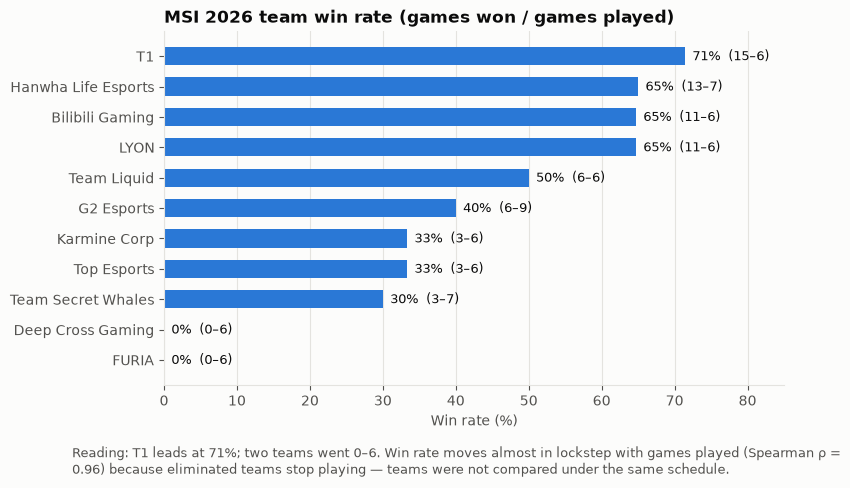

In [3]:
r_gp = rho(teams, "games_played")
d = rank.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(d.team, d.winrate, color=BLUE, height=0.6)
for y, (_, r) in enumerate(d.iterrows()):
    ax.text(r.winrate + 1, y, f"{r.winrate:.0f}%  ({r.wins}–{r.loses})", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 85); ax.set_xlabel("Win rate (%)"); ax.grid(axis="y", visible=False)
ax.set_title("MSI 2026 team win rate (games won / games played)")
finish(fig, f"Reading: T1 leads at {rank.winrate.iloc[0]:.0f}%; two teams went 0–6. Win rate moves almost in lockstep "
            f"with games played (Spearman ρ = {r_gp:.2f}) because eliminated teams stop playing — "
            "teams were not compared under the same schedule.", "01_team_winrate.png")

**Note on the format.** Win rate and games played are almost the same ranking. Teams that lost early played fewer games against different opponents, so any metric that rises with "how far a team got" will also rise with win rate. Keep this in mind for every correlation below.

### A2. Distribution of the eight metrics (one dot per team)

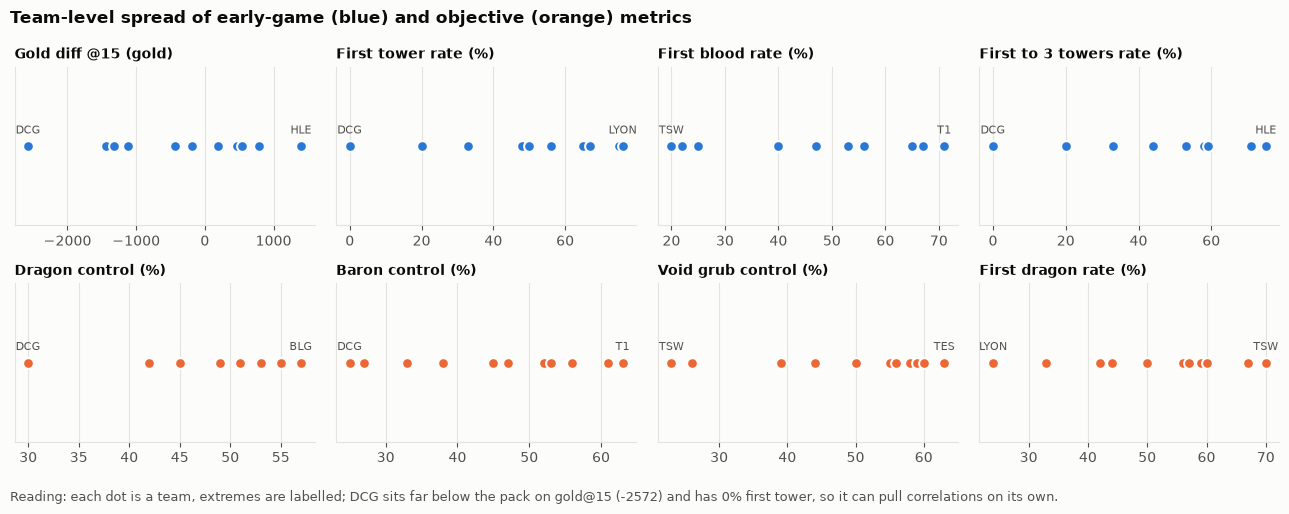

,min,50%,max,std
gold_diff_15,-2572.0,-184.0,1399.0,1176.4
first_tower_rate,0.0,50.0,76.0,27.8
first_blood_rate,20.0,53.0,71.0,19.2
first_to_three_towers_rate,0.0,44.0,75.0,25.9
dragon_control_rate,30.0,51.0,57.0,7.7
baron_control_rate,25.0,47.0,63.0,13.2
grub_control_rate,23.0,55.0,63.0,13.8
first_dragon_rate,24.0,56.0,70.0,14.2


In [4]:
fig, axes = plt.subplots(2, 4, figsize=(13, 4.8))
for ax, m in zip(axes.flat, EARLY + OBJ):
    v = teams[[m, "abbr"]].sort_values(m)
    ax.scatter(v[m], np.zeros(len(v)), s=60, color=GCOLOR[GROUP[m]], edgecolor=SURF, linewidth=1.5, zorder=3)
    lo, hi = v.iloc[0], v.iloc[-1]
    ax.annotate(lo.abbr, (lo[m], 0), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8, color=INK2)
    ax.annotate(hi.abbr, (hi[m], 0), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=8, color=INK2)
    ax.set_yticks([]); ax.set_ylim(-1, 1); ax.grid(axis="y", visible=False)
    ax.set_title(LABEL[m], fontsize=10, color=INK)
fig.suptitle("Team-level spread of early-game (blue) and objective (orange) metrics", x=0.01, ha="left",
             fontweight="bold", color=INK)
fig.tight_layout()
finish(fig, "Reading: each dot is a team, extremes are labelled; DCG sits far below the pack on gold@15 "
            f"({teams.loc[teams.abbr=='DCG','gold_diff_15'].item():.0f}) and has 0% first tower, so it can pull correlations on its own.")
teams[EARLY + OBJ].describe().T[["min", "50%", "max", "std"]].round(1)

### A3. Players and champions (context for the backup questions)

In [5]:
pos = (players.groupby("position")[["gold_diff_10", "cs_diff_10", "kda", "damage_share"]]
       .agg(["median", "min", "max"]).round(1))
pos

gold_diff_10           cs_diff_10               kda            \
               median  min  max     median   min  max median  min  max   
position                                                                 
ADC            -121.0 -438  382       -1.6 -12.2  6.4    3.5  1.9  5.4   
Jungle           -7.0 -254  173       -0.8  -5.2  3.5    3.1  1.4  4.8   
Middle            6.0 -263  188       -1.2  -7.2  6.9    3.7  1.3  7.2   
Support           2.0 -199  152        0.1  -3.4  2.9    3.4  1.4  4.2   
Top             -45.0 -390  268       -0.3  -7.0  6.3    2.4  1.1  3.7   

         damage_share              
               median   min   max  
position                           
ADC              27.0  23.8  32.3  
Jungle           18.0  14.8  19.4  
Middle           26.0  22.4  27.3  
Support           8.3   7.2   9.9  
Top              21.7  19.9  24.9

In [6]:
gp = champs.games_played
print(f"Champions with ≥1 game: {len(champs)} | ≥5 games: {(gp >= 5).sum()} | max games: {gp.max()}")
pd.cut(gp, [0, 1, 4, 9, 14, 19], labels=["1", "2–4", "5–9", "10–14", "15–19"]).value_counts().sort_index().rename("champions")

Champions with ≥1 game: 101 | ≥5 games: 63 | max games: 19


games_played
1        15
2–4      23
5–9      31
10–14    21
15–19    11
Name: champions, dtype: int64

## Part B — Main question (Step 6)

### B1. Spearman ρ with win rate, leave-one-out stability, and a check without the two 6-game teams

In [7]:
sub6 = teams[teams.games_played > 6]          # drops DCG and FURIA (0–6, eliminated early)
rows = []
for m in EARLY + OBJ:
    full = rho(teams, m)
    loo = pd.Series({t: rho(teams[teams.team != t], m) for t in teams.team})
    swing = (loo - full).abs().idxmax()
    rows.append({"group": GROUP[m], "metric": m, "rho": full,
                 "loo_min": loo.min(), "loo_max": loo.max(), "loo_range": loo.max() - loo.min(),
                 "most_influential_team": ABBR[swing], "rho_without_6game_teams": rho(sub6, m)})
res = pd.DataFrame(rows)
res["sign_flips_in_loo"] = (res.loo_min < 0) & (res.loo_max > 0)
res.round(2)

,group,metric,rho,loo_min,loo_max,loo_range,most_influential_team,rho_without_6game_teams,sign_flips_in_loo
0,Early game,gold_diff_15,0.85,0.80,0.95,0.15,KC,0.75,False
1,Early game,first_tower_rate,0.55,0.40,0.68,0.28,TSW,0.18,False
2,Early game,first_blood_rate,0.14,-0.15,0.40,0.54,T1,0.77,True
3,Early game,first_to_three_towers_rate,0.95,0.93,0.97,0.04,G2,0.90,False
4,Objective control,dragon_control_rate,0.48,0.34,0.61,0.27,HLE,0.46,False
5,Objective control,baron_control_rate,0.87,0.83,0.91,0.08,HLE,0.87,False
6,Objective control,grub_control_rate,0.32,0.18,0.46,0.28,TES,0.45,False
7,Objective control,first_dragon_rate,-0.17,-0.33,0.05,0.38,FUR,-0.01,True


In [8]:
grp = res.groupby("group").agg(mean_rho=("rho", "mean"), median_rho=("rho", "median"),
                               max_rho=("rho", "max"), mean_loo_range=("loo_range", "mean")).round(2)
grp

,mean_rho,median_rho,max_rho,mean_loo_range
group,,,,
Early game,0.62,0.7,0.95,0.25
Objective control,0.37,0.4,0.87,0.25


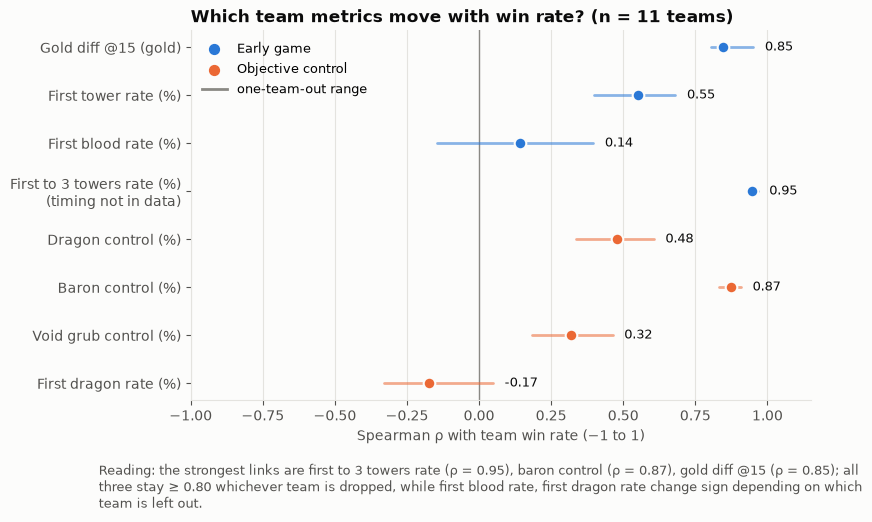

In [9]:
d = res.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.axvline(0, color=MUTED, linewidth=1)
for y, r in d.iterrows():
    c = GCOLOR[r.group]
    ax.plot([r.loo_min, r.loo_max], [y, y], color=c, linewidth=2, solid_capstyle="round", alpha=0.55)
    ax.scatter(r.rho, y, s=70, color=c, edgecolor=SURF, linewidth=1.5, zorder=3)
    ax.text(max(r.loo_max, r.rho) + 0.04, y, f"{r.rho:.2f}", va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(d)), [LABEL[m] + ("\n(timing not in data)" if m == "first_to_three_towers_rate" else "") for m in d.metric])
ax.set_xlim(-1, 1.15); ax.set_xlabel("Spearman ρ with team win rate (−1 to 1)"); ax.grid(axis="y", visible=False)
for g, c in GCOLOR.items():
    ax.scatter([], [], color=c, s=50, label=g)
ax.plot([], [], color=MUTED, linewidth=2, label="one-team-out range")
ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.set_title("Which team metrics move with win rate? (n = 11 teams)")
top = res.sort_values("rho", ascending=False).head(3)
flips = ", ".join(LABEL[m].split(" (")[0].lower() for m in res.loc[res.sign_flips_in_loo, "metric"])
finish(fig, "Reading: the strongest links are " + ", ".join(f"{LABEL[m].split(' (')[0].lower()} (ρ = {v:.2f})" for m, v in zip(top.metric, top.rho))
            + f"; all three stay ≥ {top.loo_min.min():.2f} whichever team is dropped, while {flips} change sign depending on which team is left out.",
       "02_spearman_by_metric.png")

### B1b. Game length context — what does "early" mean in these games?

Only one team metric has a fixed timestamp: `gold_diff_15` (minute 15). The "first X" and "first to three towers" metrics have **no time in the data**, so we cannot tell how early they happened. Here we place minute 15 inside the average game and check whether game length itself moves with win rate or the metrics.

In [10]:
dur = teams[["team", "abbr", "games_played", "winrate", "average_game_duration"]].copy()
dur["min15_pct_of_game"] = (15 / dur.average_game_duration * 100).round(1)
w_mean = (dur.average_game_duration * dur.games_played).sum() / dur.games_played.sum()
print(f"Average game length: {dur.average_game_duration.min()}–{dur.average_game_duration.max()} min across teams; "
      f"game-weighted mean {w_mean:.1f} min → minute 15 is ~{15 / w_mean * 100:.0f}% of an average game "
      f"(range {dur.min15_pct_of_game.min()}–{dur.min15_pct_of_game.max()}%).")
dur_rho = teams[["winrate"] + EARLY + OBJ].corrwith(teams.average_game_duration, method="spearman").round(2).rename("rho_with_game_length")
print(f"Largest |ρ| between game length and any of these: {dur_rho.abs().max():.2f}")
TIMING = {"gold_diff_15": "fixed: minute 15", "first_tower_rate": "untimed event", "first_blood_rate": "untimed event",
          "first_to_three_towers_rate": "untimed event", "first_dragon_rate": "untimed event",
          "dragon_control_rate": "whole-game share", "baron_control_rate": "whole-game share",
          "grub_control_rate": "whole-game share"}
res["timing_in_data"] = res.metric.map(TIMING)
display(dur.sort_values("average_game_duration").reset_index(drop=True))
pd.concat([dur_rho, res.set_index("metric")[["timing_in_data"]]], axis=1)

Average game length: 30.4–34.7 min across teams; game-weighted mean 32.5 min → minute 15 is ~46% of an average game (range 43.2–49.3%).
Largest |ρ| between game length and any of these: 0.29


,team,abbr,games_played,winrate,average_game_duration,min15_pct_of_game
0,Deep Cross Gaming,DCG,6,0.00,30.4,49.3
1,Team Secret Whales,TSW,10,30.00,30.8,48.7
2,Hanwha Life Esports,HLE,20,65.00,30.9,48.5
3,Team Liquid,TL,12,50.00,31.3,47.9
4,Karmine Corp,KC,9,33.33,31.7,47.3
5,LYON,LYON,17,64.71,32.8,45.7
6,Bilibili Gaming,BLG,17,64.71,33.1,45.3
7,T1,T1,21,71.43,33.3,45.0
8,Top Esports,TES,9,33.33,33.8,44.4
9,G2 Esports,G2,15,40.00,34.5,43.5


,rho_with_game_length,timing_in_data
winrate,0.07,NaN
gold_diff_15,0.06,fixed: minute 15
first_tower_rate,0.04,untimed event
first_blood_rate,0.26,untimed event
first_to_three_towers_rate,-0.05,untimed event
dragon_control_rate,0.11,whole-game share
baron_control_rate,0.14,whole-game share
grub_control_rate,0.29,whole-game share
first_dragon_rate,-0.15,untimed event


### B2. The two headline scatters

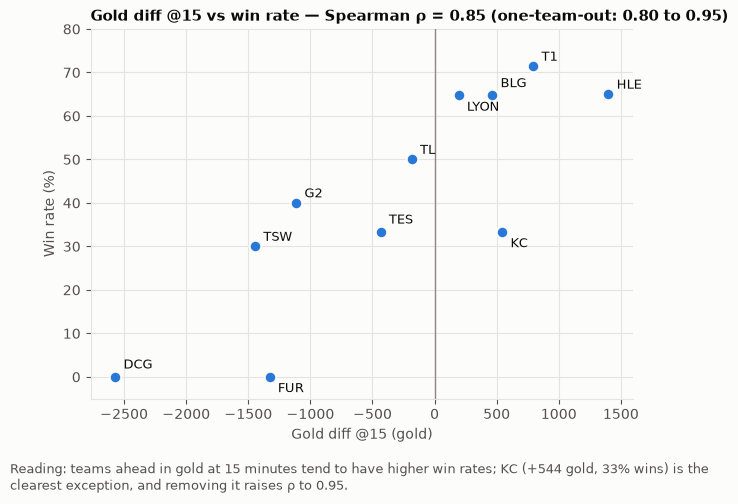

In [11]:
OFFSET = {"BLG": (6, 6), "LYON": (6, -11), "DCG": (6, 6), "FUR": (6, -11), "KC": (6, -11), "TES": (6, 6)}

def scatter(m):
    r = res.set_index("metric").loc[m]
    fig, ax = plt.subplots(figsize=(7, 4.8))
    ax.scatter(teams[m], teams.winrate, s=70, color=GCOLOR[GROUP[m]], edgecolor=SURF, linewidth=1.5, zorder=3)
    for _, t in teams.iterrows():
        ax.annotate(t.abbr, (t[m], t.winrate), xytext=OFFSET.get(t.abbr, (6, 4)), textcoords="offset points",
                    fontsize=9, color=INK)
    ax.set_xlabel(LABEL[m]); ax.set_ylabel("Win rate (%)"); ax.set_ylim(-5, 80)
    ax.set_title(f"{LABEL[m].split(' (')[0]} vs win rate — Spearman ρ = {r.rho:.2f} "
                 f"(one-team-out: {r.loo_min:.2f} to {r.loo_max:.2f})", fontsize=11)
    return fig, ax, r

fig, ax, r = scatter("gold_diff_15")
ax.axvline(0, color=MUTED, linewidth=1)
finish(fig, f"Reading: teams ahead in gold at 15 minutes tend to have higher win rates; KC (+{teams.loc[teams.abbr=='KC','gold_diff_15'].item():.0f} gold, "
            f"{teams.loc[teams.abbr=='KC','winrate'].item():.0f}% wins) is the clearest exception, and removing it raises ρ to {rho(teams[teams.abbr != 'KC'], 'gold_diff_15'):.2f}.",
       "03_gold15_vs_winrate.png")

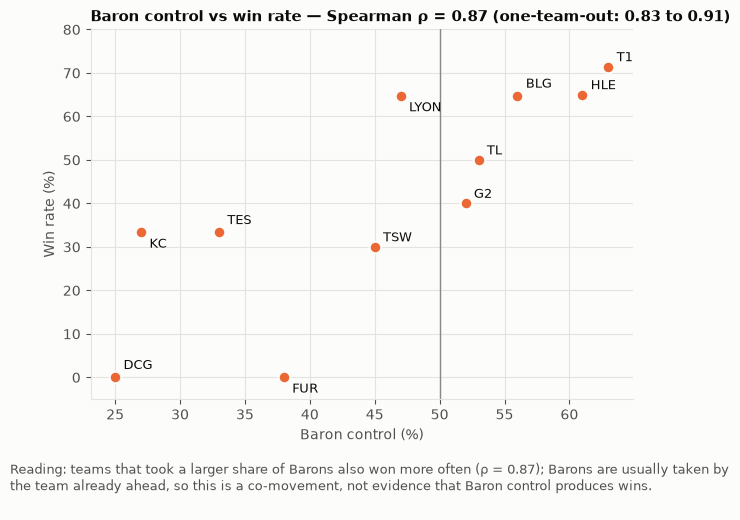

In [12]:
fig, ax, r = scatter("baron_control_rate")
ax.axvline(50, color=MUTED, linewidth=1)
finish(fig, f"Reading: teams that took a larger share of Barons also won more often (ρ = {r.rho:.2f}); "
            "Barons are usually taken by the team already ahead, so this is a co-movement, not evidence that Baron control produces wins.",
       "04_baron_vs_winrate.png")

### B3. How much do the metrics overlap? (Spearman between metrics)

In [13]:
inter = teams[EARLY + OBJ].corr(method="spearman").round(2)
inter.columns = [c.replace("_rate", "") for c in inter.columns]
inter

,gold_diff_15,first_tower,first_blood,first_to_three_towers,dragon_control,baron_control,grub_control,first_dragon
gold_diff_15,1.00,0.52,0.10,0.90,0.62,0.64,0.21,0.01
first_tower_rate,0.52,1.00,-0.30,0.61,0.03,0.26,0.05,-0.55
first_blood_rate,0.10,-0.30,1.00,0.09,0.12,0.14,0.67,0.09
first_to_three_towers_rate,0.90,0.61,0.09,1.00,0.58,0.81,0.27,-0.05
dragon_control_rate,0.62,0.03,0.12,0.58,1.00,0.61,-0.19,0.70
baron_control_rate,0.64,0.26,0.14,0.81,0.61,1.00,0.21,0.10
grub_control_rate,0.21,0.05,0.67,0.27,-0.19,0.21,1.00,-0.30
first_dragon_rate,0.01,-0.55,0.09,-0.05,0.70,0.10,-0.30,1.00


In [14]:
pairs = (teams[EARLY + OBJ].corr(method="spearman").where(lambda x: np.triu(np.ones(x.shape, bool), 1))
         .stack().rename("rho").sort_values(ascending=False))
print("Most overlapping metric pairs:")
print(pairs.head(4).round(2).to_string())

Most overlapping metric pairs:
gold_diff_15                first_to_three_towers_rate    0.90
first_to_three_towers_rate  baron_control_rate            0.81
dragon_control_rate         first_dragon_rate             0.70
first_blood_rate            grub_control_rate             0.67


### B4. Summary printed from the numbers above

In [15]:
s = res.set_index("metric")
print(f"Mean ρ — early game: {grp.loc['Early game','mean_rho']:.2f} | objective control: {grp.loc['Objective control','mean_rho']:.2f}")
print(f"Top 3 metrics: " + ", ".join(f"{m} {s.loc[m,'rho']:.2f}" for m in res.sort_values('rho', ascending=False).metric[:3]))
print(f"Sign flips under leave-one-out: {list(res.loc[res.sign_flips_in_loo, 'metric'])}")
print(f"Without DCG+FURIA (n={len(sub6)}): " + ", ".join(f"{m} {v:.2f}" for m, v in zip(res.metric, res.rho_without_6game_teams)))
print(f"games_played vs winrate ρ = {r_gp:.2f}")
print(f"gold_diff_15 vs first_to_three_towers ρ = {rho(teams, 'gold_diff_15', 'first_to_three_towers_rate'):.2f}; "
      f"first_to_three_towers vs baron ρ = {rho(teams, 'first_to_three_towers_rate', 'baron_control_rate'):.2f}")

Mean ρ — early game: 0.62 | objective control: 0.37
Top 3 metrics: first_to_three_towers_rate 0.95, baron_control_rate 0.87, gold_diff_15 0.85
Sign flips under leave-one-out: ['first_blood_rate', 'first_dragon_rate']
Without DCG+FURIA (n=9): gold_diff_15 0.75, first_tower_rate 0.18, first_blood_rate 0.77, first_to_three_towers_rate 0.90, dragon_control_rate 0.46, baron_control_rate 0.87, grub_control_rate 0.45, first_dragon_rate -0.01
games_played vs winrate ρ = 0.96
gold_diff_15 vs first_to_three_towers ρ = 0.90; first_to_three_towers vs baron ρ = 0.81


### B6. Backup questions

1. Among champions with at least 5 games, is pick+ban rate related to win rate?
2. Which role's gold difference at 10 minutes moves most with team win rate?

Same rules as above: Spearman, descriptive. Stability is checked by varying the game threshold (Q1) and by removing one team at a time (Q2).

In [16]:
rows = []
for k in [3, 5, 8, 10]:
    c = champs[champs.games_played >= k]
    rows.append({"min_games": k, "n_champions": len(c), "rho_pickban_vs_winrate": round(rho(c, "pick_ban_rate"), 2),
                 "rho_pick_vs_winrate": round(rho(c, "pick_rate"), 2), "rho_ban_vs_winrate": round(rho(c, "ban_rate"), 2)})
champ_rho = pd.DataFrame(rows)
champ_rho

,min_games,n_champions,rho_pickban_vs_winrate,rho_pick_vs_winrate,rho_ban_vs_winrate
0,3,78,0.27,0.19,0.30
1,5,63,0.45,0.26,0.44
2,8,41,0.41,0.26,0.41
3,10,32,0.25,0.01,0.30


In [17]:
pt = players.merge(teams[["team", "winrate"]].rename(columns={"winrate": "team_winrate"}), on="team")
rows = []
for pos, g in pt.groupby("position"):
    full = rho(g, "gold_diff_10", "team_winrate")
    loo = [rho(g[g.team != t], "gold_diff_10", "team_winrate") for t in g.team]
    rows.append({"position": pos, "n_players": len(g), "rho_gd10_vs_team_winrate": round(full, 2),
                 "loo_min": round(min(loo), 2), "loo_max": round(max(loo), 2)})
role_rho = pd.DataFrame(rows).sort_values("rho_gd10_vs_team_winrate", ascending=False).reset_index(drop=True)
role_rho

,position,n_players,rho_gd10_vs_team_winrate,loo_min,loo_max
0,ADC,11,0.88,0.84,0.95
1,Top,11,0.57,0.43,0.76
2,Jungle,11,0.38,0.24,0.68
3,Middle,11,0.14,-0.02,0.42
4,Support,11,-0.00,-0.17,0.31


In [18]:
c5 = champ_rho.set_index("min_games").loc[5]
top = role_rho.iloc[0]
print(f"Backup 1: {int(c5.n_champions)} champions with ≥5 games, pick+ban vs win rate ρ = {c5.rho_pickban_vs_winrate:.2f} "
      f"(range {champ_rho.rho_pickban_vs_winrate.min():.2f}–{champ_rho.rho_pickban_vs_winrate.max():.2f} across thresholds 3–10)")
print(f"Backup 2: {top.position} gold@10 moves most with team win rate, ρ = {top.rho_gd10_vs_team_winrate:.2f} "
      f"(one-team-out {top.loo_min:.2f}–{top.loo_max:.2f}); lowest: {role_rho.iloc[-1].position} ρ = {role_rho.iloc[-1].rho_gd10_vs_team_winrate:.2f}")

Backup 1: 63 champions with ≥5 games, pick+ban vs win rate ρ = 0.45 (range 0.25–0.45 across thresholds 3–10)
Backup 2: ADC gold@10 moves most with team win rate, ρ = 0.88 (one-team-out 0.84–0.95); lowest: Support ρ = -0.00


### B5. Interpretation (descriptive)

*Every number here comes from the cells above. Correlations describe co-movement among 11 teams; they are not effects.*

- **Neither group stands out as a block.** The split is not "early vs objectives" but **"sustained lead" vs "first event"**: gold at 15, first to three towers and Baron control all move strongly with win rate and stay stable under leave-one-out. One-off "first" events (first blood, first dragon) are weak and change sign depending on which team is removed.
- **Game length sets what "early" means.** Games averaged about 32.5 minutes, so minute 15 is close to the **midpoint** of a game (43–49% depending on team), not its opening. Gold at 15 is the only metric with a known timestamp, and it is the cleanest "early" evidence we have: teams ahead near the halfway mark tend to win more.
- **First to three towers is reported separately, not as early-game evidence.** It has the strongest link, but the data does not say when it happens, and it overlaps strongly with both gold at 15 and Baron control (B3). It reads as "who builds a lead first", somewhere between early and mid game.
- **Game length does not move with win rate or any of the metrics** (largest |ρ| in B1b), so the results above are not a side effect of some teams playing shorter or longer games.
- **On average the early group sits higher** (mean ρ in the group table), but a mean of four correlations is a crude summary; it is pulled up by first-to-three-towers.
- **First tower is fragile:** moderate with all 11 teams, but it drops sharply once the two 0–6 teams are removed, while first blood does the opposite.

**Limitations:** n = 11; win rate ≈ games played (format/opponent bias); objectives are often taken *because* a team is ahead (reverse causality); team averages hide game-level dynamics; event timings are not in the data.